In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
train_dir = "../dataset/Train_Set"

classes = ["Aman", "Lainnya", "Rusak"]
image_paths = []
labels = []
for class_name in classes:
    class_dir = os.path.join(train_dir, class_name)
    for filename in os.listdir(class_dir):
        image_path = os.path.join(class_dir, filename)
        image_paths.append(image_path)
        labels.append(class_name)
df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})
print("Total gambar:", len(df))

Total gambar: 12224


In [3]:
from PIL import Image

bad_files = []

for filepath in df["filepath"]:

    try:
        # Cek dengan PIL
        with Image.open(filepath) as img:
            img.verify()

        # Cek lagi dengan TensorFlow
        image_bytes = tf.io.read_file(filepath)

        image = tf.image.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        _ = image.numpy()

    except Exception as e:
        bad_files.append({
            "filepath": filepath,
            "error": str(e)
        })

print("Jumlah file bermasalah:", len(bad_files))

for item in bad_files:
    print(item["filepath"])
    print(item["error"])
    print()

Jumlah file bermasalah: 1
../dataset/Train_Set\Aman\Aman_06692.jpg
{{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 



In [4]:
bad_paths = [item["filepath"] for item in bad_files]

df = df[
    ~df["filepath"].isin(bad_paths)
].copy()

print("Total gambar setelah cleaning:", len(df))

Total gambar setelah cleaning: 12223


In [5]:
bad_files = []

for filepath in df["filepath"]:
    try:
        image_bytes = tf.io.read_file(filepath)

        image = tf.image.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        _ = image.numpy()

    except Exception:
        bad_files.append(filepath)

print("Jumlah file bermasalah:", len(bad_files))

for filepath in bad_files:
    print(filepath)

Jumlah file bermasalah: 0


In [6]:
df = df[~df["filepath"].isin(bad_files)].copy()

print("Total gambar setelah cleaning:", len(df))

Total gambar setelah cleaning: 12223


### encode

In [7]:
label_map = {
    "Aman": 0,
    "Lainnya": 1,
    "Rusak": 2
}

df["label_id"] = df["label"].map(label_map)

print(df.head())

                                   filepath label  label_id
0  ../dataset/Train_Set\Aman\Aman_00001.jpg  Aman         0
1  ../dataset/Train_Set\Aman\Aman_00002.png  Aman         0
2  ../dataset/Train_Set\Aman\Aman_00003.jpg  Aman         0
3  ../dataset/Train_Set\Aman\Aman_00004.jpg  Aman         0
4  ../dataset/Train_Set\Aman\Aman_00005.jpg  Aman         0


### split

In [8]:
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label_id"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))

Training: 9778
Validation: 2445


In [9]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_df["label_id"]
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(0.4630392574702846), 1: np.float64(9.642998027613412), 2: np.float64(1.35748993474941)}


In [10]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [11]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [12]:
train_paths = train_df["filepath"].values
train_labels = train_df["label_id"].values

val_paths = val_df["filepath"].values
val_labels = val_df["label_id"].values

In [13]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

In [14]:
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [15]:
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [16]:
images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Image min:", tf.reduce_min(images).numpy())
print("Image max:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image min: 0.0
Image max: 1.0


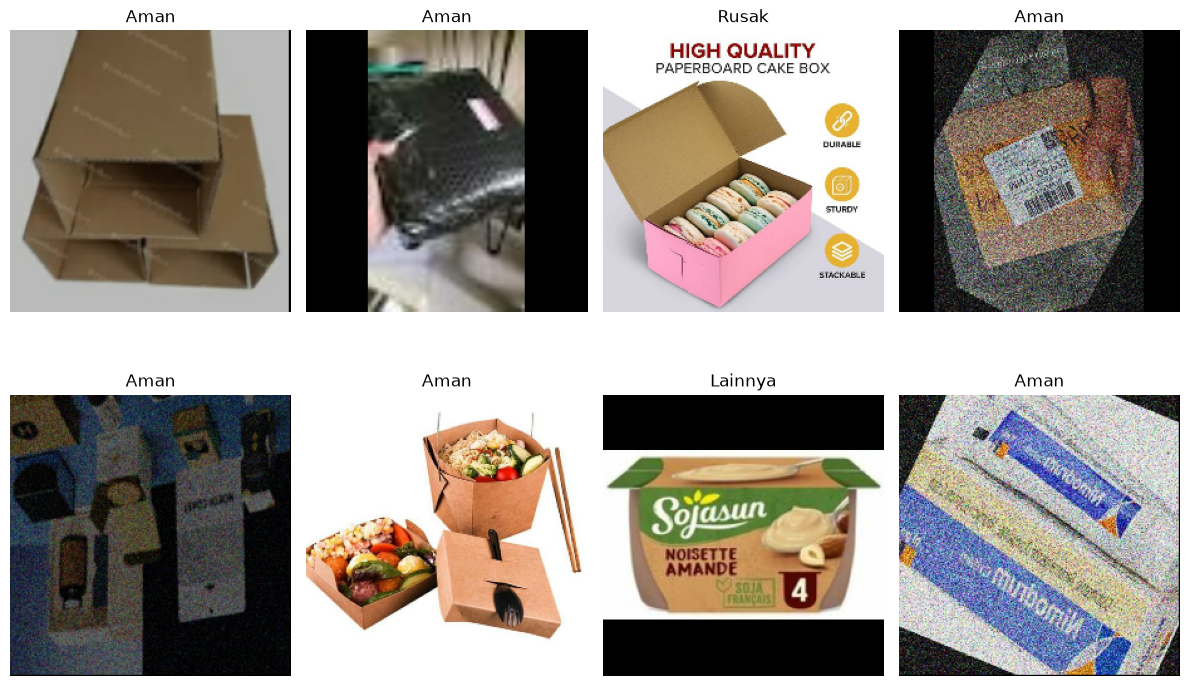

In [17]:
plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i])
    plt.title(classes[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(
        0.03,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

sample_image = images[0]

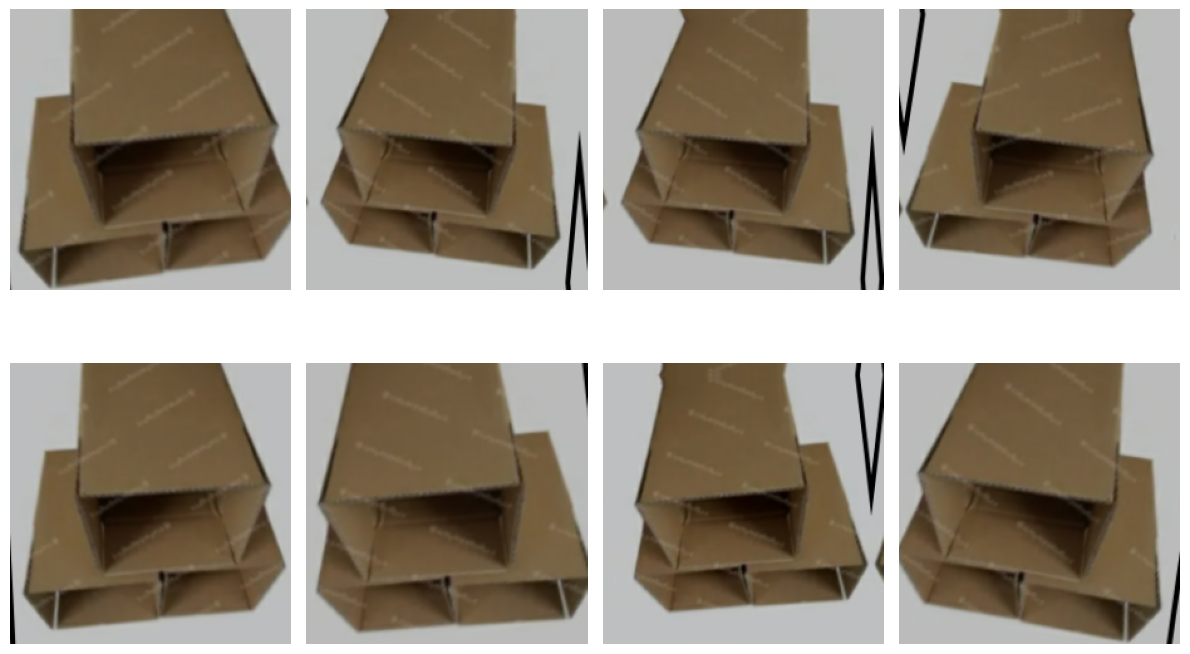

In [19]:
plt.figure(figsize=(12, 8))

for i in range(8):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 4, i + 1)
    plt.imshow(augmented_image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
NUM_CLASSES = 3

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

# Buat model
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = data_augmentation(inputs)
x = x * 255.0
x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)
model = models.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [21]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [23]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [24]:
moderate_class_weights = {
    0: 0.70,
    1: 3.00,
    2: 1.30
}

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=moderate_class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10


d:\JamTerbang\datascape\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


306/306 ━━━━━━━━━━━━━━━━━━━━ 221s 691ms/step - accuracy: 0.7329 - loss: 0.6478 - val_accuracy: 0.7930 - val_loss: 0.5140 - learning_rate: 0.0010
Epoch 2/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 259s 842ms/step - accuracy: 0.7790 - loss: 0.5480 - val_accuracy: 0.7767 - val_loss: 0.5298 - learning_rate: 0.0010
Epoch 3/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 230s 743ms/step - accuracy: 0.7891 - loss: 0.5231 - val_accuracy: 0.8070 - val_loss: 0.4840 - learning_rate: 0.0010
Epoch 4/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 209s 681ms/step - accuracy: 0.7945 - loss: 0.5132 - val_accuracy: 0.7767 - val_loss: 0.5318 - learning_rate: 0.0010
Epoch 5/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 210s 682ms/step - accuracy: 0.7964 - loss: 0.4998 - val_accuracy: 0.7738 - val_loss: 0.5271 - learning_rate: 0.0010
Epoch 6/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 206s 669ms/step - accuracy: 0.8022 - loss: 0.4891 - val_accuracy: 0.7751 - val_loss: 0.5264 - learning_rate: 5.0000e-04


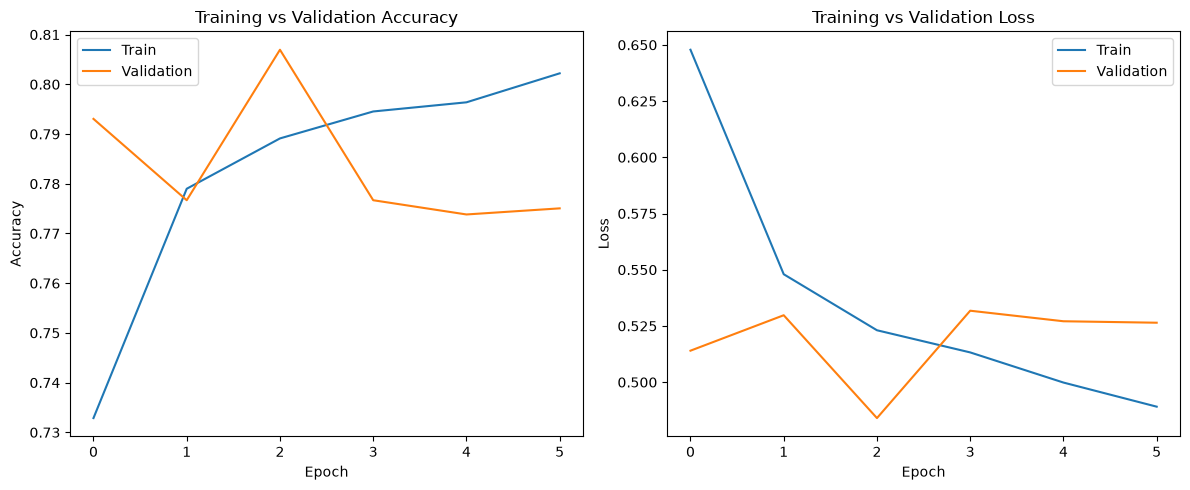

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])

plt.tight_layout()
plt.show()

In [26]:
y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [27]:
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

print("Macro F1:", macro_f1)

Macro F1: 0.7123450423971046


In [28]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4
    )
)

              precision    recall  f1-score   support

        Aman     0.8802    0.8597    0.8698      1760
     Lainnya     0.5413    0.6941    0.6082        85
       Rusak     0.6499    0.6683    0.6590       600

    accuracy                         0.8070      2445
   macro avg     0.6905    0.7407    0.7123      2445
weighted avg     0.8119    0.8070    0.8090      2445



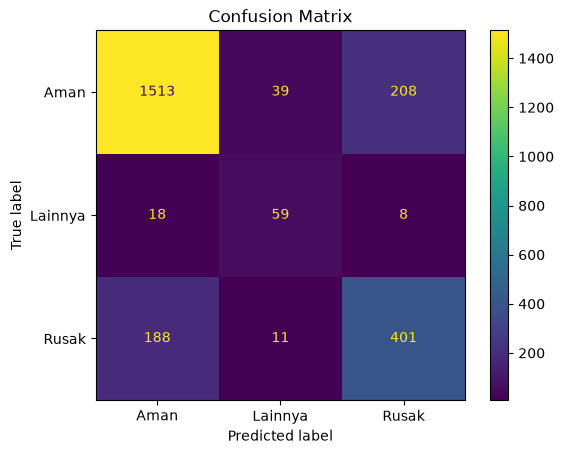

In [29]:
cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

### base model Macro F1: 0.6742493629465406
